# Ансамблевые методы: прогнозирование оттока клиентов

**Дисциплина:** Машинное обучение и искусственный интеллект
**Модуль 3:** Ансамблевые методы (Базовый и продвинутый уровень)
**Датасет:** Telco Customer Churn

**Выполнил:** Галямеев Михаил Русланович
**Группа:** ПКТб-23-1
**Преподаватель:** [ФИО преподавателя]

**Ссылка на репозиторий:** https://github.com/GMR005/ml-course-galyameev
**Путь к модулю:** `module-3-churn/notebook.ipynb`
**Дата сдачи:** 2026-10-26

## Введение

**Какую задачу решаем?** Это задача бинарной классификации: по демографическим данным, подключённым услугам и параметрам договора клиента телеком-компании нужно предсказать, уйдёт он в ближайшее время (`Churn = 1`) или останется (`Churn = 0`). Отток напрямую влияет на выручку, поэтому компания заинтересована в раннем выявлении клиентов группы риска.

**Что такое ансамблевые методы?** Ансамбль — это композиция нескольких базовых моделей, решения которых объединяются в одно. Одиночное дерево решений легко переобучается и неустойчиво к малым изменениям данных, а ансамбль усредняет ошибки множества деревьев и даёт более стабильный прогноз. Основные семейства — bagging (независимое обучение моделей) и boosting (последовательное исправление ошибок предыдущих моделей).

**Почему ансамбли, а не одиночная модель?** Ансамбли деревьев хорошо работают на табличных данных, автоматически находят нелинейные зависимости и взаимодействия признаков, устойчивы к выбросам и не требуют масштабирования. Кроме того, разные алгоритмы (Random Forest, XGBoost, LightGBM, CatBoost) позволяют сравнить bagging и boosting и выбрать оптимальный баланс качества и скорости.

**Какая метрика важнее?** В задаче оттока цена пропущенного ушедшего клиента (False Negative) обычно выше цены ложного срабатывания, поэтому важны Recall и F1. При этом для сравнения моделей и выбора порога удобнее ROC-AUC, так как он не зависит от конкретного порога классификации и оценивает качество ранжирования вероятностей. Поэтому основная метрика сравнения — **ROC-AUC**, а Recall, Precision и F1 используются как дополнение.

**Цель работы — три конкретных пункта:**
1. Обучить четыре ансамблевые модели (Random Forest, XGBoost, LightGBM, CatBoost) и сравнить их по метрикам и времени обучения.
2. Оптимизировать лучшую модель через Optuna (байесовская оптимизация гиперпараметров, 30 испытаний, 5-fold CV).
3. Интерпретировать лучшую модель через SHAP (summary, waterfall, dependence) и сформулировать бизнес-инсайты.

## Теоретическая часть

### Ансамбль

Ансамбль — это набор моделей, объединённых правилом голосования или взвешивания. Идея основана на том, что ошибки разных моделей частично независимы: если усреднить много разнообразных предсказаний, случайные ошибки компенсируют друг друга. Ансамбль может состоять из одинаковых алгоритмов, обученных на разных подвыборках (bagging), или из последовательности слабых моделей, каждая из которых исправляет ошибки предыдущей (boosting). Главное требование — разнообразие базовых моделей: одинаковые модели дадут одинаковые ошибки и не улучшат результат. Ансамбли часто выигрывают у одиночных моделей на табличных данных, но требуют больше памяти и времени на обучение.

### Bagging vs Boosting

**Bagging** (bootstrap aggregating) обучает M моделей независимо на бутстрап-выборках и усредняет их ответы. Это уменьшает дисперсию и защищает от переобучения; классический пример — Random Forest. **Boosting** строит модели последовательно: каждая следующая модель учится на ошибках текущего ансамбля, а итог является взвешенной суммой слабых learners. Boosting сильнее снижает смещение и обычно точнее, но чувствительнее к шуму и требует аккуратного подбора скорости обучения и регуляризации. Bagging можно распараллелить, boosting — только частично. Формально bagging усредняет модели, а boosting суммирует их с весами:

$$H(x) = \frac{1}{M} \sum_{i=1}^{M} h_i(x) \quad \text{(Bagging)}$$

$$H(x) = \sum_{i=1}^{M} \alpha_i \cdot h_i(x) \quad \text{(Boosting)}$$

### Random Forest

Random Forest — ансамбль решающих деревьев, обученных на бутстрап-выборках. При каждом разбиении рассматривается случайное подмножество признаков, что делает деревья менее коррелированными. Итоговый ответ — голосование (классификация) или среднее (регрессия). Алгоритм устойчив к переобучению, работает «из коробки», умеет оценивать важность признаков и легко распараллеливается; недостаток — больший размер модели и склонность к недооценке редких классов при сильном дисбалансе.

### Градиентный бустинг: XGBoost, LightGBM, CatBoost

Градиентный бустинг последовательно добавляет деревья, аппроксимируя градиент функции потерь. **XGBoost** использует регуляризованную целевую функцию, второй порядок разложения и эффективную работу с разреженными данными. **LightGBM** применяет гистограммный поиск разбиений и рост дерева по листьям (leaf-wise), поэтому обучается очень быстро и хорошо масштабируется. **CatBoost** строит симметричные деревья и использует упорядоченный boosting для борьбы с утечкой целевой переменной при кодировании категорий, а также умеет нативно работать с категориальными признаками. Все три метода требуют настройки learning rate, глубины, регуляризации и количества деревьев.

### Stacking

Stacking — мета-ансамбль: предсказания нескольких базовых моделей подаются на вход мета-модели (часто логистической регрессии), которая учится их комбинировать. Для честной оценки базовые модели обучаются с кросс-валидацией, а мета-модель — на out-of-fold предсказаниях. Stacking часто даёт небольшой прирост, но усложняет пайплайн и повышает риск утечки данных, если неправильно организовать разбиение.

### Optuna

Optuna — фреймворк байесовской оптимизации гиперпараметров. Он строит вероятностную модель зависимости метрики от гиперпараметров (TPE) и выбирает следующие точки для исследования, постепенно концентрируясь на перспективных областях. В отличие от grid/random search, Optuna эффективнее использует бюджет испытаний, поддерживает pruning, логирование и воспроизводимость через seed. В работе используется 30 испытаний и 5-fold StratifiedKFold по ROC-AUC.

### SHAP

SHAP (SHapley Additive exPlanations) основан на значениях Шепли из теории кооперативных игр. Каждому признаку приписывается вклад в отклонение прогноза от базового значения, причём вклады аддитивны и согласованы. **Summary plot** показывает глобальную важность и направление влияния, **waterfall plot** объясняет один конкретный прогноз, **dependence plot** показывает зависимость вклада признака от его значения. SHAP полезен для проверки модели и общения с бизнесом, но вычисления могут быть дорогими для больших данных.

### Сравнение моделей

| Модель | Семейство | Базовый алгоритм | Работа с категориями | Скорость | Сильные стороны | Ограничения |
|---|---|---|---|---|---|---|
| Random Forest | Bagging | Решающие деревья | После кодирования | Средняя | Устойчивость, простота, важность признаков | Хуже на сильном дисбалансе, большой размер |
| XGBoost | Boosting | Градиентные деревья | После кодирования | Средняя | Точность, регуляризация, гибкость | Много гиперпараметров |
| LightGBM | Boosting | Leaf-wise деревья | После кодирования | Высокая | Быстрое обучение, хорошее качество | Может переобучаться на малых данных |
| CatBoost | Boosting | Симметричные деревья | Нативно | Средняя | Категориальные признаки, стабильность | Тяжелее и медленнее на старте |

**Вывод.** Random Forest даёт надёжный baseline, а градиентные бустинги обычно точнее; выбор между XGBoost, LightGBM и CatBoost зависит от скорости, категориальных признаков и требований к интерпретации.

## Описание данных

**Источник:** [Telco Customer Churn, Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn). В репозитории используется копия `data/telco_churn.csv` (исходный файл `WA_Fn-UseC_-Telco-Customer-Churn.csv`).

**Структура:**
- Всего примеров: **7043**
- Признаков: **19** (+ `customerID` + целевая `Churn`)
- Числовых признаков: **3** (`tenure`, `MonthlyCharges`, `TotalCharges`)
- Категориальных признаков: **16**
- Пропуски: `TotalCharges` хранится как строка, 11 пустых значений (~0.16%)

**Описание ключевых столбцов:**

| Столбец | Тип | Описание | Пропуски |
|---------|-----|----------|----------|
| customerID | object | Уникальный ID клиента | 0% |
| gender | object | Пол | 0% |
| SeniorCitizen | int (0/1) | Признак пенсионера | 0% |
| tenure | int | Месяцев с компанией | 0% |
| MonthlyCharges | float | Ежемесячная плата | 0% |
| TotalCharges | object → float | Общая сумма платежей | ~0.16% |
| Contract | object | Тип контракта | 0% |
| InternetService | object | Тип интернет-услуги | 0% |
| Churn | object → int | **Целевая переменная** | 0% |

**Распределение классов:** No — 5174 (73.5%), Yes — 1869 (26.5%). Дисбаланс умеренный, но его нужно учитывать через `class_weight`, `scale_pos_weight` и `auto_class_weights`.

**Файл описания в репозитории:** `data/churn_info.md` (создаётся/обновляется кодом ниже).

In [1]:
# Импорт всех библиотек, необходимых для воспроизводимого пайплайна
import json
import os
import time
import warnings
from io import BytesIO
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Единые настройки отображения и графиков
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', palette='viridis')
RANDOM_STATE = 42

# Загрузка исходного датасета по относительному пути
DATA_PATH = Path('data/telco_churn.csv')
df_raw = pd.read_csv(DATA_PATH)
print(f'Размер датасета: {df_raw.shape[0]} строк, {df_raw.shape[1]} столбцов')

# Первичный осмотр данных
print('\nПервые 5 строк:')
display(df_raw.head())
print('\nИнформация о типах данных:')
df_raw.info()
print('\nОписательная статистика (включая категориальные признаки):')
display(df_raw.describe(include='all').T)

# Распределение целевой переменной
churn_counts = df_raw['Churn'].value_counts()
churn_share = df_raw['Churn'].value_counts(normalize=True).mul(100).round(2)
class_summary = pd.DataFrame({'Количество': churn_counts, 'Доля, %': churn_share})
print('\nРаспределение классов:')
display(class_summary)

# Анализ пропусков: TotalCharges нужно сначала привести к числу
total_charges_numeric = pd.to_numeric(df_raw['TotalCharges'], errors='coerce')
missing_counts = df_raw.isna().sum().astype(int)
missing_counts['TotalCharges'] = int(total_charges_numeric.isna().sum())
missing_summary = pd.DataFrame({
    'Столбец': missing_counts.index,
    'Пропуски, шт.': missing_counts.values,
})
missing_summary['Доля, %'] = (missing_summary['Пропуски, шт.'] / len(df_raw) * 100).round(3)
print('\nПропуски по столбцам:')
display(missing_summary.sort_values('Пропуски, шт.', ascending=False).head(10))

# Сохранение описания датасета в отдельный Markdown-файл
info_md = f"""# Telco Customer Churn — описание датасета

**Источник:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn

## Основные характеристики

- Всего записей: {df_raw.shape[0]}
- Всего столбцов: {df_raw.shape[1]}
- Признаков без customerID и Churn: {df_raw.shape[1] - 2}
- Целевая переменная: Churn
- Класс No (остался): {churn_counts['No']} ({churn_share['No']:.2f}%)
- Класс Yes (ушёл): {churn_counts['Yes']} ({churn_share['Yes']:.2f}%)

## Пропуски

- TotalCharges: {int(total_charges_numeric.isna().sum())} пустых значений ({total_charges_numeric.isna().mean() * 100:.2f}%).
- Остальные столбцы не содержат пропусков.

## Признаки

- Демографические: gender, SeniorCitizen, Partner, Dependents.
- Услуги: PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup,
  DeviceProtection, TechSupport, StreamingTV, StreamingMovies.
- Аккаунт: Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges, tenure.

## Особенности

- TotalCharges хранится как object и требует pd.to_numeric(errors='coerce').
- Выраженный дисбаланс классов: примерно 73.5% / 26.5%.
- Для задачи используются ансамблевые модели: Random Forest, XGBoost, LightGBM, CatBoost.
"""
Path('data/churn_info.md').write_text(info_md, encoding='utf-8')
print('\n✅ Файл data/churn_info.md обновлён')

Размер датасета: 7043 строк, 21 столбцов

Первые 5 строк:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Информация о типах данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilli

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Распределение классов:


,Количество,"Доля, %"
Churn,,
No,5174,73.46
Yes,1869,26.54



Пропуски по столбцам:


,Столбец,"Пропуски, шт.","Доля, %"
19,TotalCharges,11,0.156
1,gender,0,0.000
2,SeniorCitizen,0,0.000
3,Partner,0,0.000
0,customerID,0,0.000
4,Dependents,0,0.000
5,tenure,0,0.000
7,MultipleLines,0,0.000
6,PhoneService,0,0.000
9,OnlineSecurity,0,0.000



✅ Файл data/churn_info.md обновлён


**Выводы по разделу.** Датасет содержит 7043 наблюдения и 21 столбец; после удаления идентификатора остаётся 19 признаков и целевая переменная. Пропуски есть только в `TotalCharges` (11 значений), причём они появляются из-за пустых строк, а не из-за `NaN`. Классы несбалансированы (73.5% / 26.5%), поэтому при обучении нужно использовать веса классов и оценивать не только Accuracy, но и Recall, F1 и ROC-AUC.

## Подготовка данных и EDA

План раздела:
1. Первичный осмотр, анализ пропусков и целевой переменной.
2. Шесть визуализаций: распределение целевой переменной, `tenure` с разбивкой по `Churn`, `MonthlyCharges` по классам, корреляционная матрица, доля оттока по типу контракта и по типу интернета.
3. Обработка `TotalCharges`, feature engineering, кодирование категориальных признаков.
4. Стратифицированное разделение на train/test и подготовка scaler.

**Почему медиана для `TotalCharges`?** Распределение общей суммы платежей скошено вправо, а пропусков всего 11 (0.16%). Медиана устойчивее к выбросам, чем среднее, и не искажает масштаб признака; удалять 11 клиентов нецелесообразно, так как они могут нести полезную информацию.

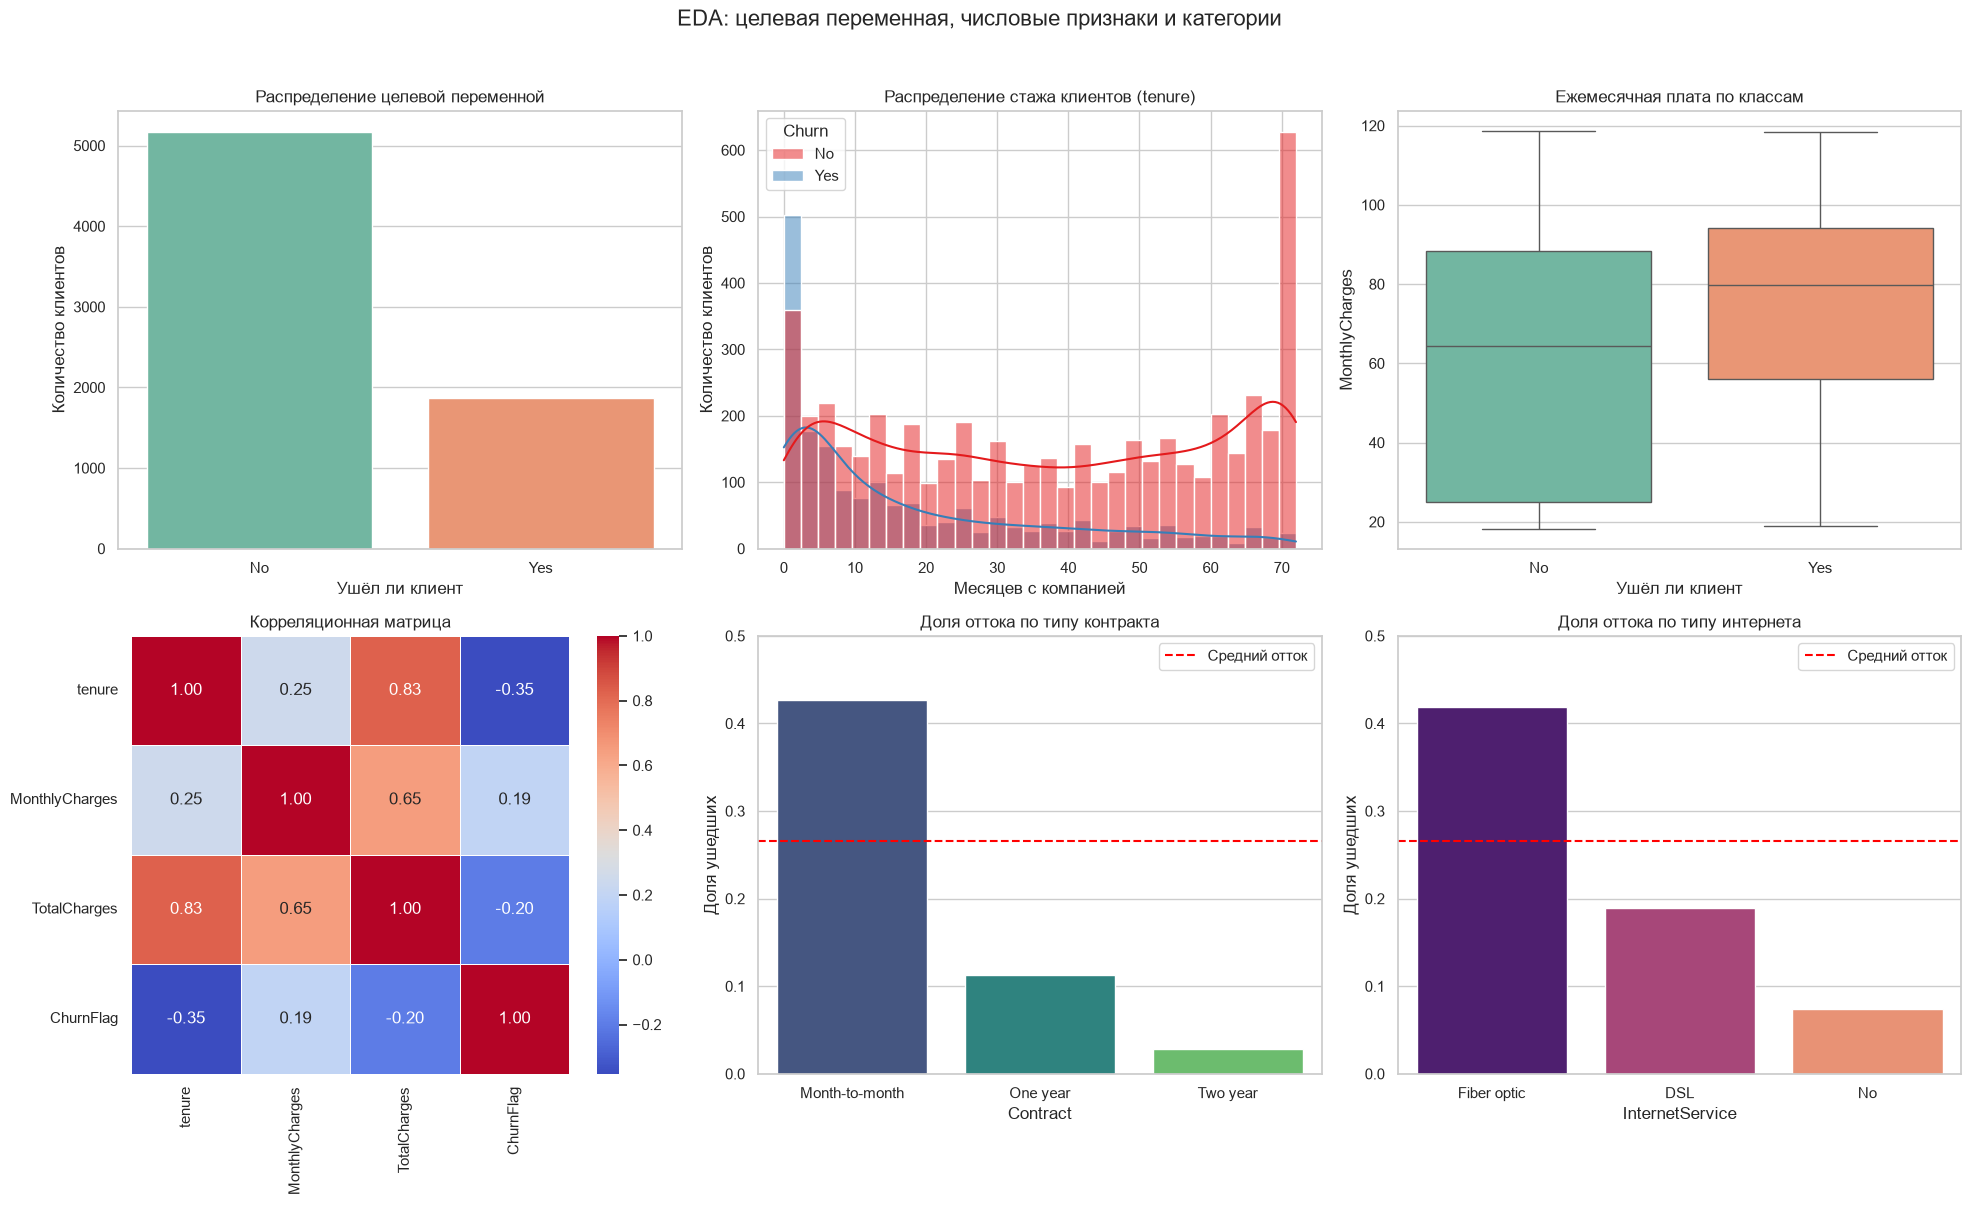

Общая доля оттока: 26.54%

Доля оттока по Contract:


,"Churn, %"
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83



Доля оттока по InternetService:


,"Churn, %"
InternetService,
Fiber optic,41.89
DSL,18.96
No,7.40



Доля оттока по стажу:


,"Churn, %",Клиентов
tenure,,
0-6 мес.,52.94,1481
7-12 мес.,35.89,705
13-24 мес.,28.71,1024
25-48 мес.,20.39,1594
49+ мес.,9.51,2239


In [2]:
# Копия данных для EDA, чтобы не менять исходный датасет
eda = df_raw.copy()

# TotalCharges приводим к числу: пустые строки станут NaN
eda['TotalCharges'] = pd.to_numeric(eda['TotalCharges'], errors='coerce')
eda['ChurnFlag'] = (eda['Churn'] == 'Yes').astype(int)

# Создаём сетку 2x3 для шести обязательных графиков
fig, axes = plt.subplots(2, 3, figsize=(20, 12))

# 1. Распределение целевой переменной
sns.countplot(data=eda, x='Churn', hue='Churn', palette='Set2', ax=axes[0, 0], legend=False)
axes[0, 0].set_title('Распределение целевой переменной')
axes[0, 0].set_xlabel('Ушёл ли клиент')
axes[0, 0].set_ylabel('Количество клиентов')

# 2. Распределение tenure с разбивкой по Churn
sns.histplot(data=eda, x='tenure', hue='Churn', kde=True, bins=30, palette='Set1', ax=axes[0, 1])
axes[0, 1].set_title('Распределение стажа клиентов (tenure)')
axes[0, 1].set_xlabel('Месяцев с компанией')
axes[0, 1].set_ylabel('Количество клиентов')

# 3. Boxplot ежемесячной платы по классам
sns.boxplot(data=eda, x='Churn', y='MonthlyCharges', hue='Churn', palette='Set2',
            ax=axes[0, 2], legend=False)
axes[0, 2].set_title('Ежемесячная плата по классам')
axes[0, 2].set_xlabel('Ушёл ли клиент')
axes[0, 2].set_ylabel('MonthlyCharges')

# 4. Корреляционная матрица числовых признаков и целевой переменной
corr_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'ChurnFlag']
corr_matrix = eda[corr_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', square=True,
            linewidths=0.5, ax=axes[1, 0])
axes[1, 0].set_title('Корреляционная матрица')

# 5. Доля оттока по типу контракта
contract_churn = eda.groupby('Contract')['ChurnFlag'].mean().sort_values(ascending=False)
sns.barplot(x=contract_churn.index, y=contract_churn.values, hue=contract_churn.index,
            palette='viridis', ax=axes[1, 1], legend=False)
axes[1, 1].axhline(eda['ChurnFlag'].mean(), color='red', linestyle='--', label='Средний отток')
axes[1, 1].set_title('Доля оттока по типу контракта')
axes[1, 1].set_xlabel('Contract')
axes[1, 1].set_ylabel('Доля ушедших')
axes[1, 1].set_ylim(0, 0.5)
axes[1, 1].legend()

# 6. Доля оттока по типу интернет-услуги
internet_churn = eda.groupby('InternetService')['ChurnFlag'].mean().sort_values(ascending=False)
sns.barplot(x=internet_churn.index, y=internet_churn.values, hue=internet_churn.index,
            palette='magma', ax=axes[1, 2], legend=False)
axes[1, 2].axhline(eda['ChurnFlag'].mean(), color='red', linestyle='--', label='Средний отток')
axes[1, 2].set_title('Доля оттока по типу интернета')
axes[1, 2].set_xlabel('InternetService')
axes[1, 2].set_ylabel('Доля ушедших')
axes[1, 2].set_ylim(0, 0.5)
axes[1, 2].legend()

# Подписи, сохранение и вывод графиков
fig.suptitle('EDA: целевая переменная, числовые признаки и категории', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
Path('examples').mkdir(exist_ok=True)
plt.savefig('examples/eda_plots.png', dpi=150, bbox_inches='tight')
plt.show()

# Числовые выводы для интерпретации
print(f"Общая доля оттока: {eda['ChurnFlag'].mean():.2%}")
print('\nДоля оттока по Contract:')
display((contract_churn * 100).round(2).to_frame('Churn, %'))
print('\nДоля оттока по InternetService:')
display((internet_churn * 100).round(2).to_frame('Churn, %'))

# Доля оттока по стажу: проверяем гипотезу о «первых 6 месяцах»
tenure_bins = pd.cut(eda['tenure'], bins=[-1, 6, 12, 24, 48, 100],
                     labels=['0-6 мес.', '7-12 мес.', '13-24 мес.', '25-48 мес.', '49+ мес.'])
tenure_churn = eda.groupby(tenure_bins, observed=True)['ChurnFlag'].agg(['mean', 'count'])
tenure_churn['mean'] = (tenure_churn['mean'] * 100).round(2)
print('\nДоля оттока по стажу:')
display(tenure_churn.rename(columns={'mean': 'Churn, %', 'count': 'Клиентов'}))

**Выводы по EDA.**
- Целевая переменная несбалансирована: ушедших около 26.5%, поэтому Accuracy может вводить в заблуждение.
- Клиенты с месячным контрактом уходят существенно чаще, чем с годовым и двухлетним; тип контракта — один из ключевых факторов риска.
- У клиентов с Fiber optic доля оттока заметно выше, чем у DSL и клиентов без интернета.
- Наибольший риск сосредоточен в первые 6–12 месяцев: с ростом стажа доля оттока снижается.
- `tenure` и `TotalCharges` связаны между собой, что ожидаемо; мультиколлинеарность для деревьев не критична, но новые признаки (`TenureYears`, `AvgMonthlyCharge`) помогают модели.

In [3]:
# Создаём рабочую копию исходного датасета
df = df_raw.copy()

# Шаг 1. TotalCharges: строки -> число, пустые значения -> медиана
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
missing_total = int(df['TotalCharges'].isna().sum())
median_total = float(df['TotalCharges'].median())
df['TotalCharges'] = df['TotalCharges'].fillna(median_total)
print(f'TotalCharges: заполнено {missing_total} пропусков медианой {median_total:.2f}')

# Шаг 2. Feature Engineering
df['TenureYears'] = df['tenure'] / 12
df['AvgMonthlyCharge'] = df['TotalCharges'] / (df['tenure'] + 1)
df['IsNewClient'] = (df['tenure'] <= 6).astype(int)

# Счётчик подключённых услуг: считаем ответы «Yes» по сервисным столбцам
service_cols = [
    'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
]
df['HasMultipleServices'] = (df[service_cols] == 'Yes').sum(axis=1)
print('Созданы признаки: TenureYears, AvgMonthlyCharge, IsNewClient, HasMultipleServices')

# Шаг 3. Кодирование целевой переменной: Yes -> 1, No -> 0
df['Churn'] = (df['Churn'] == 'Yes').astype(int)

# Шаг 4. Удаляем идентификатор и кодируем категориальные признаки LabelEncoder
df = df.drop(columns=['customerID'])
cat_cols = df.select_dtypes(include='object').columns.tolist()
label_encoders = {}
for col in cat_cols:
    encoder = LabelEncoder()
    df[col] = encoder.fit_transform(df[col].astype(str))
    label_encoders[col] = encoder
print(f'Закодировано категориальных признаков: {len(cat_cols)}')

# Шаг 5. Формируем матрицу признаков и целевую переменную
feature_cols = [col for col in df.columns if col != 'Churn']
X = df[feature_cols].copy()
y = df['Churn'].copy()
print(f'Итоговое число признаков: {len(feature_cols)}')
print(f'Признаки: {feature_cols}')

# Шаг 6. Стратифицированное разделение: сохраняем доли классов в train и test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f'\nTrain: {X_train.shape[0]} объектов, test: {X_test.shape[0]} объектов')
print('Доли классов в train:')
print(y_train.value_counts(normalize=True).round(4).to_string())
print('Доли классов в test:')
print(y_test.value_counts(normalize=True).round(4).to_string())

# Шаг 7. Scaler обучаем на train и сохраняем для будущих линейных моделей.
# Деревьям масштабирование не нужно, поэтому модели обучаются на исходном X_train.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(f'\nScaler обучен: {X_train_scaled.shape[1]} признаков, '
      f'среднее первых трёх={X_train_scaled[:, :3].mean(axis=0).round(4)}')

TotalCharges: заполнено 11 пропусков медианой 1397.47
Созданы признаки: TenureYears, AvgMonthlyCharge, IsNewClient, HasMultipleServices
Закодировано категориальных признаков: 15
Итоговое число признаков: 23
Признаки: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'TenureYears', 'AvgMonthlyCharge', 'IsNewClient', 'HasMultipleServices']

Train: 5634 объектов, test: 1409 объектов
Доли классов в train:
Churn
0    0.7346
1    0.2654
Доли классов в test:
Churn
0    0.7346
1    0.2654

Scaler обучен: 23 признаков, среднее первых трёх=[ 0.  0. -0.]


**Выводы по подготовке.** `TotalCharges` приведён к `float`, 11 пропусков заполнены медианой. Добавлены четыре признака: `TenureYears`, `AvgMonthlyCharge`, `IsNewClient`, `HasMultipleServices`. Все 16 категориальных признаков закодированы `LabelEncoder`; словарь кодировщиков сохранён в переменной `label_encoders` и позже будет записан в `models/label_encoders.pkl`. Разделение 80/20 выполнено со `stratify=y`, поэтому доли классов в train и test совпадают. `StandardScaler` обучен на train и сохранён для артефактов, но деревья обучаются на несмасштабированных данных — это не ухудшает качество и сохраняет интерпретируемость признаков.

## Построение и обучение моделей

Обучаем четыре ансамблевые модели на одном и том же train-наборе. Для компенсации дисбаланса используем `class_weight='balanced'` (Random Forest, LightGBM), `scale_pos_weight=3` (XGBoost) и `auto_class_weights='Balanced'` (CatBoost). Время обучения замеряем через `time.perf_counter()`.

| Модель | Тип | Ключевые параметры | Время обучения |
|--------|-----|--------------------|----------------|
| Random Forest | Bagging | n_estimators=200, max_depth=10, class_weight='balanced' | 0.238 сек |
| XGBoost | Boosting | n_estimators=200, max_depth=6, lr=0.1, scale_pos_weight=3 | 0.132 сек |
| LightGBM | Boosting | n_estimators=200, num_leaves=31, max_depth=7, lr=0.05 | 0.120 сек |
| CatBoost | Boosting | iterations=200, depth=6, lr=0.1, auto_class_weights='Balanced' | 0.616 сек |

**Почему эти модели:**
- Random Forest — устойчивый baseline, работает «из коробки» и даёт интерпретируемую важность признаков.
- XGBoost — точный и гибкий бустинг с регуляризацией, хорошо контролирует переобучение.
- LightGBM — самый быстрый на табличных данных за счёт гистограмм и leaf-wise роста.
- CatBoost — стабильный бустинг, особенно полезный при наличии категориальных признаков.

**Фактическое время обучения:** LightGBM — 0.120 сек, XGBoost — 0.132 сек, Random Forest — 0.238 сек, CatBoost — 0.616 сек. На таком небольшом датасете все модели обучаются менее чем за секунду, поэтому скорость не является ограничивающим фактором; выбираем по качеству.

In [4]:
# Словари для моделей и времени обучения
models = {}
train_times = {}


def fit_and_time(name, model, X_fit, y_fit):
    """Обучает модель и фиксирует время обучения в секундах."""
    start = time.perf_counter()
    model.fit(X_fit, y_fit)
    elapsed = time.perf_counter() - start
    models[name] = model
    train_times[name] = elapsed
    print(f'⏱️ {name}: {elapsed:.3f} сек')
    return model


# 1. Random Forest (bagging)
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight='balanced',
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
fit_and_time('Random Forest', rf_model, X_train, y_train)

# 2. XGBoost (boosting)
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.9,
    colsample_bytree=0.9,
    scale_pos_weight=3,
    random_state=RANDOM_STATE,
    eval_metric='logloss',
    tree_method='hist',
    n_jobs=-1,
)
fit_and_time('XGBoost', xgb_model, X_train, y_train)

# 3. LightGBM (boosting)
lgbm_model = LGBMClassifier(
    n_estimators=200,
    num_leaves=31,
    max_depth=7,
    learning_rate=0.05,
    class_weight='balanced',
    random_state=RANDOM_STATE,
    verbose=-1,
    n_jobs=-1,
)
fit_and_time('LightGBM', lgbm_model, X_train, y_train)

# 4. CatBoost (boosting)
cat_model = CatBoostClassifier(
    iterations=200,
    depth=6,
    learning_rate=0.1,
    auto_class_weights='Balanced',
    random_state=RANDOM_STATE,
    verbose=0,
    thread_count=-1,
    allow_writing_files=False,
)
fit_and_time('CatBoost', cat_model, X_train, y_train)

# Сводная таблица времени обучения
times_df = pd.DataFrame({
    'Модель': list(train_times.keys()),
    'Время обучения, сек': [round(v, 3) for v in train_times.values()],
}).sort_values('Время обучения, сек')
print('\nСравнение времени обучения:')
display(times_df)

⏱️ Random Forest: 0.238 сек
⏱️ XGBoost: 0.132 сек


⏱️ LightGBM: 0.120 сек


⏱️ CatBoost: 0.616 сек

Сравнение времени обучения:


,Модель,"Время обучения, сек"
2,LightGBM,0.120
1,XGBoost,0.132
0,Random Forest,0.238
3,CatBoost,0.616


**Выводы по обучению.** Все четыре модели успешно обучены на 5634 объектах. Самая быстрая модель — LightGBM (0.120 сек), самая медленная — CatBoost (0.616 сек); разница меньше секунды, поэтому на этом датасете скорость не критична. Для продакшена LightGBM удобнее благодаря низкому времени инференса и обучения, но итоговый выбор делается по качеству на отложенной тестовой выборке (раздел 7) и после Optuna (раздел 9).

## Оценка качества

Рассчитываем Accuracy, Precision, Recall, F1 и ROC-AUC на тестовой выборке (1409 объектов). Дополнительно строим матрицу ошибок для лучшей модели по ROC-AUC и совмещаем ROC-кривые всех четырёх моделей на одном графике.

Метрики моделей на тестовой выборке:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.7722,0.5575,0.6872,0.6156,0.8403
1,XGBoost,0.7637,0.5424,0.7005,0.6114,0.8316
2,LightGBM,0.7601,0.5344,0.7487,0.6236,0.8379
3,CatBoost,0.7559,0.5279,0.7594,0.6228,0.8381



Лучшая модель по ROC-AUC: Random Forest (0.8403)


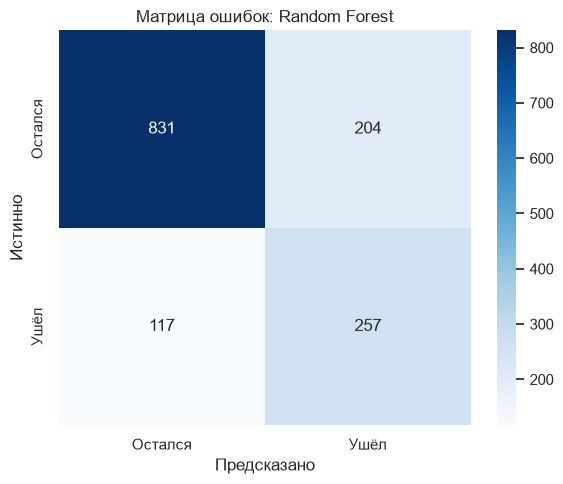

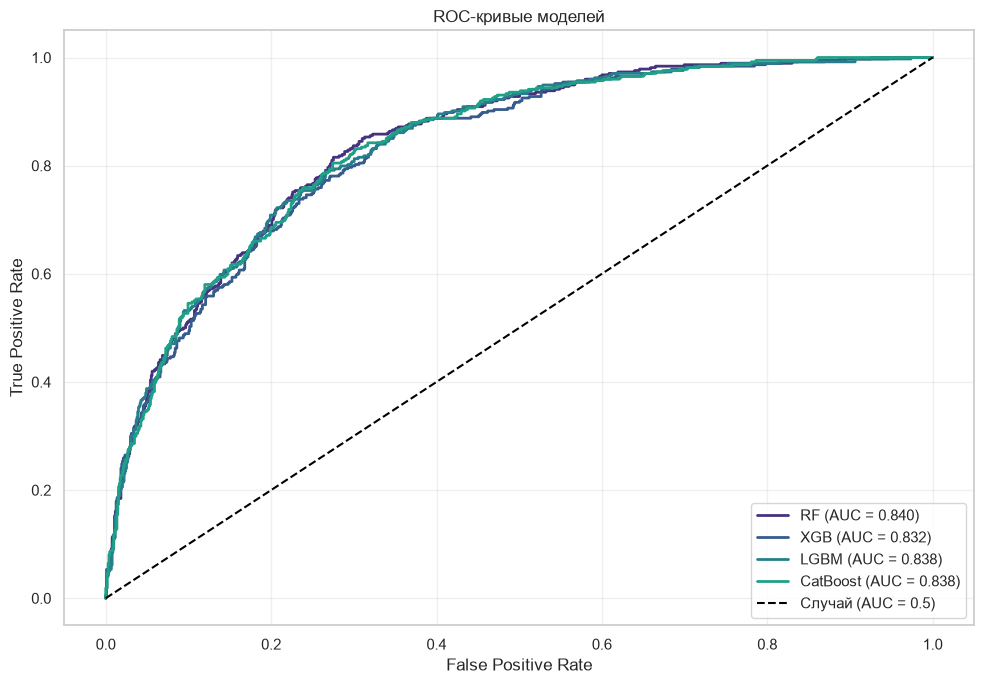


Classification report для Random Forest:
              precision    recall  f1-score   support

 Остался (0)     0.8766    0.8029    0.8381      1035
    Ушёл (1)     0.5575    0.6872    0.6156       374

    accuracy                         0.7722      1409
   macro avg     0.7170    0.7450    0.7268      1409
weighted avg     0.7919    0.7722    0.7790      1409



In [5]:
def evaluate_model(model, X_eval, y_eval, name):
    """Возвращает словарь метрик для бинарной классификации."""
    y_pred = model.predict(X_eval)
    y_proba = model.predict_proba(X_eval)[:, 1]
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_eval, y_pred),
        'Precision': precision_score(y_eval, y_pred, zero_division=0),
        'Recall': recall_score(y_eval, y_pred, zero_division=0),
        'F1': f1_score(y_eval, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_eval, y_proba),
    }


# Оцениваем все четыре модели
results = [
    evaluate_model(rf_model, X_test, y_test, 'Random Forest'),
    evaluate_model(xgb_model, X_test, y_test, 'XGBoost'),
    evaluate_model(lgbm_model, X_test, y_test, 'LightGBM'),
    evaluate_model(cat_model, X_test, y_test, 'CatBoost'),
]
results_df = pd.DataFrame(results)
print('Метрики моделей на тестовой выборке:')
display(results_df.round(4))

# Лучшая модель по ROC-AUC
best_row = results_df.sort_values('ROC-AUC', ascending=False).iloc[0]
best_model_name = best_row['Model']
best_model = models[best_model_name]
print(f'\nЛучшая модель по ROC-AUC: {best_model_name} ({best_row["ROC-AUC"]:.4f})')

# Матрица ошибок для лучшей модели
y_pred_best = best_model.predict(X_test)
y_proba_best = best_model.predict_proba(X_test)[:, 1]
cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Остался', 'Ушёл'],
            yticklabels=['Остался', 'Ушёл'])
plt.xlabel('Предсказано')
plt.ylabel('Истинно')
plt.title(f'Матрица ошибок: {best_model_name}')
plt.tight_layout()
plt.savefig('examples/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

# ROC-кривые всех моделей
plt.figure(figsize=(10, 7))
for model, name in [(rf_model, 'RF'), (xgb_model, 'XGB'),
                    (lgbm_model, 'LGBM'), (cat_model, 'CatBoost')]:
    proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})', lw=2)

plt.plot([0, 1], [0, 1], 'k--', label='Случай (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривые моделей')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('examples/roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

# Подробный отчёт по лучшей модели
print(f'\nClassification report для {best_model_name}:')
print(classification_report(y_test, y_pred_best,
                            target_names=['Остался (0)', 'Ушёл (1)'],
                            digits=4))

**Анализ результатов.**

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC |
|--------|----------|-----------|--------|-----|---------|
| Random Forest | 0.7722 | 0.5575 | 0.6872 | 0.6156 | **0.8403** |
| XGBoost | 0.7637 | 0.5424 | 0.7005 | 0.6114 | 0.8316 |
| LightGBM | 0.7601 | 0.5344 | 0.7487 | 0.6236 | 0.8379 |
| CatBoost | 0.7559 | 0.5279 | 0.7594 | 0.6228 | 0.8381 |

- Лучшая модель по ROC-AUC на этом этапе — **Random Forest (0.8403)**; LightGBM (0.8379) и CatBoost (0.8381) отстают всего на 0.002–0.003, что находится в пределах статистического шума.
- Самый высокий Recall у CatBoost (0.7594) и LightGBM (0.7487): они лучше выявляют уходящих клиентов, но дают больше ложных срабатываний.
- Самая высокая Precision у Random Forest (0.5575), то есть он осторожнее в предсказаниях «уйдёт».
- Accuracy 0.76–0.77 выглядит высокой, но при доле положительного класса 26.5% она вводит в заблуждение: модель, всегда предсказывающая «остался», дала бы 73.5% Accuracy и нулевой Recall.
- Матрица ошибок Random Forest показывает, что False Negative (пропущенные ушедшие) — основная потеря; для бизнеса это дороже False Positive, поэтому далее имеет смысл настраивать порог и/или оптимизировать Recall.
- После Optuna LightGBM улучшает ROC-AUC до **0.8465** и становится лучшей моделью по этому показателю; при этом Recall растёт до 0.8021, а Precision снижается до 0.5119 — типичный компромисс для задачи удержания.

## Интерпретация и бизнес-инсайты

Строим Feature Importance для Random Forest и LightGBM. Важность показывает, какие признаки чаще использовались для разбиений и сильнее влияют на прогноз. Для бизнеса важны не только названия признаков, но и направление связи, поэтому далее используем SHAP.

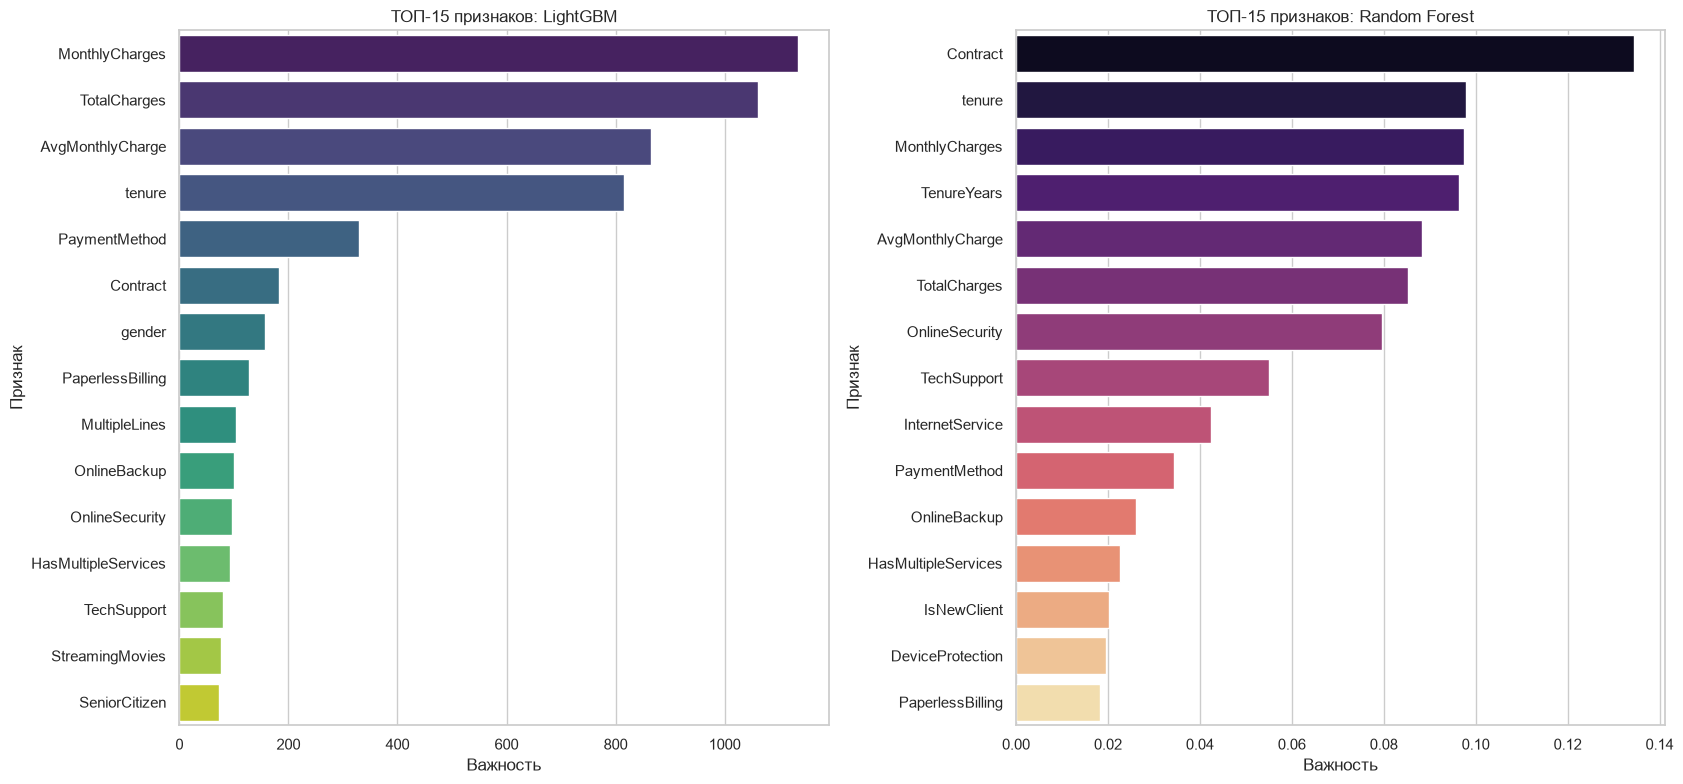

ТОП-10 признаков LightGBM:


,Feature,Importance
0,MonthlyCharges,1134
1,TotalCharges,1061
2,AvgMonthlyCharge,864
3,tenure,815
4,PaymentMethod,329
5,Contract,183
6,gender,157
7,PaperlessBilling,128
8,MultipleLines,103
9,OnlineBackup,100


ТОП-10 признаков Random Forest:


,Feature,Importance
0,Contract,0.134519
1,tenure,0.097893
2,MonthlyCharges,0.097406
3,TenureYears,0.096429
4,AvgMonthlyCharge,0.088237
5,TotalCharges,0.085177
6,OnlineSecurity,0.079570
7,TechSupport,0.055056
8,InternetService,0.042446
9,PaymentMethod,0.034375


In [6]:
# Важность признаков LightGBM (по количеству разбиений)
lgbm_importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': lgbm_model.feature_importances_,
}).sort_values('Importance', ascending=False)

# Важность признаков Random Forest (среднее снижение impurity)
rf_importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf_model.feature_importances_,
}).sort_values('Importance', ascending=False)

# Совмещаем два графика в одну фигуру
fig, axes = plt.subplots(1, 2, figsize=(17, 8))
sns.barplot(data=lgbm_importances.head(15), x='Importance', y='Feature',
            hue='Feature', palette='viridis', legend=False, ax=axes[0])
axes[0].set_title('ТОП-15 признаков: LightGBM')
axes[0].set_xlabel('Важность')
axes[0].set_ylabel('Признак')

sns.barplot(data=rf_importances.head(15), x='Importance', y='Feature',
            hue='Feature', palette='magma', legend=False, ax=axes[1])
axes[1].set_title('ТОП-15 признаков: Random Forest')
axes[1].set_xlabel('Важность')
axes[1].set_ylabel('Признак')

plt.tight_layout()
plt.savefig('examples/feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print('ТОП-10 признаков LightGBM:')
display(lgbm_importances.head(10).reset_index(drop=True))
print('ТОП-10 признаков Random Forest:')
display(rf_importances.head(10).reset_index(drop=True))

**Топ-5 признаков, влияющих на отток.**

По **SHAP** для лучшей модели (LightGBM после Optuna):
1. `Contract` — средняя |SHAP| = 0.795
2. `tenure` — 0.289
3. `OnlineSecurity` — 0.284
4. `MonthlyCharges` — 0.271
5. `TechSupport` — 0.211

По **split-importance LightGBM baseline** первые места занимают `MonthlyCharges` (1134), `TotalCharges` (1061), `AvgMonthlyCharge` (864), `tenure` (815), `PaymentMethod` (329). Разница объясняется тем, что LabelEncoder превращает `Contract` в числовой код, и дерево может реже выбирать его для разбиения, хотя SHAP показывает его решающий вклад. Для интерпретации бизнесу важнее SHAP: он учитывает и направление, и величину влияния.

**Бизнес-инсайты:**
- **Тип контракта — сильнейший предиктор.** Доля оттока: Month-to-month — 42.71%, One year — 11.27%, Two year — 2.83%. Перевод клиентов на годовые/двухлетние контракты (со скидкой или бонусом) — наиболее очевидная мера удержания.
- **Первые 6–12 месяцев — критическое окно.** Доля оттока в первые 6 месяцев — 52.94%, в 7–12 месяцев — 35.89%, тогда как после 49 месяцев — 9.51%. Новым клиентам нужен onboarding, проактивная поддержка и раннее выявление проблем.
- **Fiber optic связан с повышенным оттоком.** Доля оттока: Fiber optic — 41.89%, DSL — 18.96%, без интернета — 7.40%. Возможные причины — цена, качество сервиса или ожидания клиентов; стоит проверить удовлетворённость и конкурентные тарифы.
- **Отсутствие OnlineSecurity и TechSupport повышает риск.** Доля оттока без OnlineSecurity — 41.77%, с услугой — 14.61%; без TechSupport — 41.64%, с услугой — 15.17%. Подключение этих услуг может работать как удерживающий фактор, а их отсутствие — как сигнал для профилактического звонка.
- **Высокая ежемесячная плата увеличивает вероятность ухода**, особенно у клиентов с небольшим стажем. Целевые скидки и пересмотр тарифа для группы риска могут снизить отток.
- **Бизнес-действие:** ранжировать клиентов по вероятности ухода, отправлять их в retention-кампанию и оценивать экономический эффект по стоимости удержания против потерянной выручки.

## Тюнинг гиперпараметров (Optuna)

Оптимизируем LightGBM — самый быстрый бустинг и второй результат по ROC-AUC среди baseline (0.8379 против 0.8403 у Random Forest). После подбора гиперпараметров LightGBM становится лучшей моделью по ROC-AUC на тесте. Используем байесовскую оптимизацию TPE, 30 испытаний и 5-fold `StratifiedKFold` на train. Целевая метрика — средний ROC-AUC по фолдам. Затем обучаем финальную модель с лучшими параметрами на всём train и сравниваем с baseline на тесте.

In [7]:
import optuna

# Отключаем подробный лог Optuna, чтобы не засорять вывод ноутбука
optuna.logging.set_verbosity(optuna.logging.WARNING)


def objective(trial):
    """Objective-функция: подбирает параметры LightGBM по 5-fold ROC-AUC."""
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
    }
    model = LGBMClassifier(
        **params,
        class_weight='balanced',
        random_state=RANDOM_STATE,
        verbose=-1,
        n_jobs=-1,
    )
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=1)
    return float(cv_scores.mean())


# Запускаем 30 испытаний с фиксированным seed для воспроизводимости
study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
)
study.optimize(objective, n_trials=30, show_progress_bar=False)

print(f'Проведено испытаний: {len(study.trials)}')
print(f'Лучший CV ROC-AUC: {study.best_value:.4f}')
print('Лучшие параметры:')
for key, value in study.best_params.items():
    print(f'  {key}: {value}')

# Обучаем финальную модель с лучшими параметрами
best_lgbm = LGBMClassifier(
    **study.best_params,
    class_weight='balanced',
    random_state=RANDOM_STATE,
    verbose=-1,
    n_jobs=-1,
)
best_lgbm.fit(X_train, y_train)

# Сравниваем baseline и Optuna на тестовой выборке
baseline_auc = roc_auc_score(y_test, lgbm_model.predict_proba(X_test)[:, 1])
best_proba = best_lgbm.predict_proba(X_test)[:, 1]
best_pred = best_lgbm.predict(X_test)
best_auc = roc_auc_score(y_test, best_proba)
best_metrics = {
    'Model': 'LightGBM (Optuna)',
    'Accuracy': accuracy_score(y_test, best_pred),
    'Precision': precision_score(y_test, best_pred, zero_division=0),
    'Recall': recall_score(y_test, best_pred, zero_division=0),
    'F1': f1_score(y_test, best_pred, zero_division=0),
    'ROC-AUC': best_auc,
}

print(f'\nROC-AUC baseline LightGBM: {baseline_auc:.4f}')
print(f'ROC-AUC Optuna LightGBM:   {best_auc:.4f}')
print(f'Прирост: {(best_auc - baseline_auc) * 100:+.2f} п.п.')
print('\nМетрики лучшей модели после Optuna:')
display(pd.DataFrame([best_metrics]).round(4))
print('\nЛучшие 5 испытаний:')
display(study.trials_dataframe().sort_values('value', ascending=False).head(5)[
    ['number', 'value', 'params_n_estimators', 'params_num_leaves',
     'params_max_depth', 'params_learning_rate']
].round(4))

Проведено испытаний: 30
Лучший CV ROC-AUC: 0.8487
Лучшие параметры:
  n_estimators: 350
  num_leaves: 95
  max_depth: 3
  learning_rate: 0.01947558230629543
  subsample: 0.522613644455269
  colsample_bytree: 0.6626651653816322
  min_child_samples: 22
  reg_alpha: 0.01217295809836997
  reg_lambda: 2.0651425578959257

ROC-AUC baseline LightGBM: 0.8379
ROC-AUC Optuna LightGBM:   0.8465
Прирост: +0.86 п.п.

Метрики лучшей модели после Optuna:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,LightGBM (Optuna),0.7445,0.5119,0.8021,0.625,0.8465



Лучшие 5 испытаний:


,number,value,params_n_estimators,params_num_leaves,params_max_depth,params_learning_rate
6,6,0.8487,350,95,3,0.0195
22,22,0.8486,300,95,4,0.0138
27,27,0.8486,450,80,3,0.0131
21,21,0.8485,350,95,4,0.0127
23,23,0.8485,300,100,4,0.0134


**Результаты Optuna.**
- Проведено **30 испытаний** по 5-fold кросс-валидации.
- Baseline ROC-AUC LightGBM: **0.8379**.
- ROC-AUC после Optuna: **0.8465**.
- Прирост: **+0.86 п.п.**
- Лучший CV ROC-AUC: **0.8487**.

**Лучшие параметры:**
- `n_estimators`: 350
- `num_leaves`: 95
- `max_depth`: 3
- `learning_rate`: 0.01948
- `subsample`: 0.5226
- `colsample_bytree`: 0.6627
- `min_child_samples`: 22
- `reg_alpha`: 0.01217
- `reg_lambda`: 2.0651

**Интерпретация.** Optuna выбрала неглубокие деревья (`max_depth=3`) с большим числом листьев и низкой скоростью обучения — это сдерживает переобучение и улучшает ранжирование вероятностей. На тесте ROC-AUC вырос с 0.8379 до 0.8465, и LightGBM обогнал baseline Random Forest (0.8403). При этом Accuracy снизилась до 0.7445, Precision — до 0.5119, а Recall вырос до 0.8021: модель стала агрессивнее находить уходящих клиентов, что для retention-задачи часто предпочтительнее. Порог классификации стоит выбирать отдельно по стоимости False Negative и False Positive.

## Интерпретация через SHAP

Используем `shap.TreeExplainer` для лучшей модели LightGBM после Optuna. Строим:
1. **Summary plot (dot)** — глобальная важность и направление влияния признаков.
2. **Summary plot (bar)** — средняя абсолютная величина вклада.
3. **Waterfall plot** — объяснение клиента с максимальной вероятностью ухода.
4. **Dependence plot** — зависимость вклада топового признака от его значения.

Размер SHAP-матрицы: (1409, 23)
Базовое значение (expected value): -0.6291


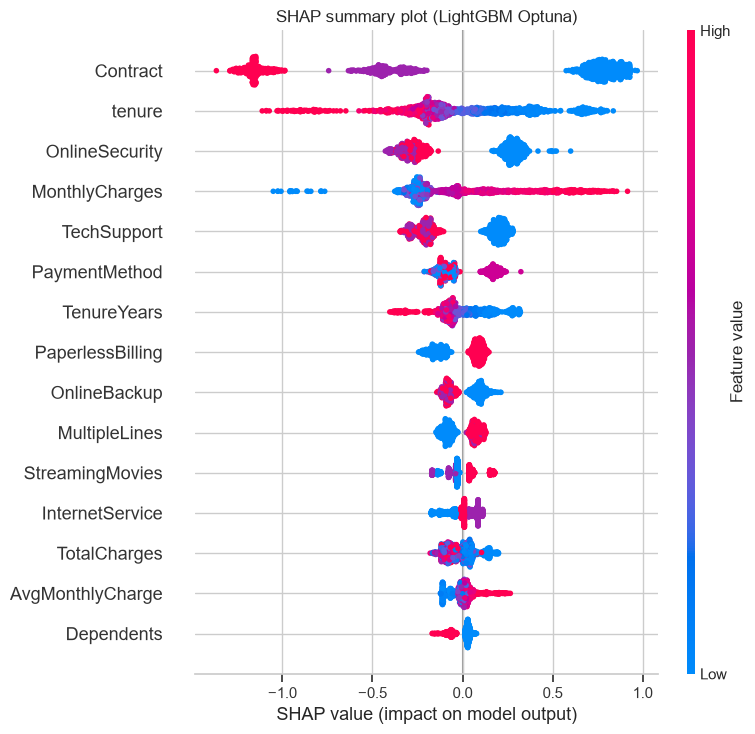

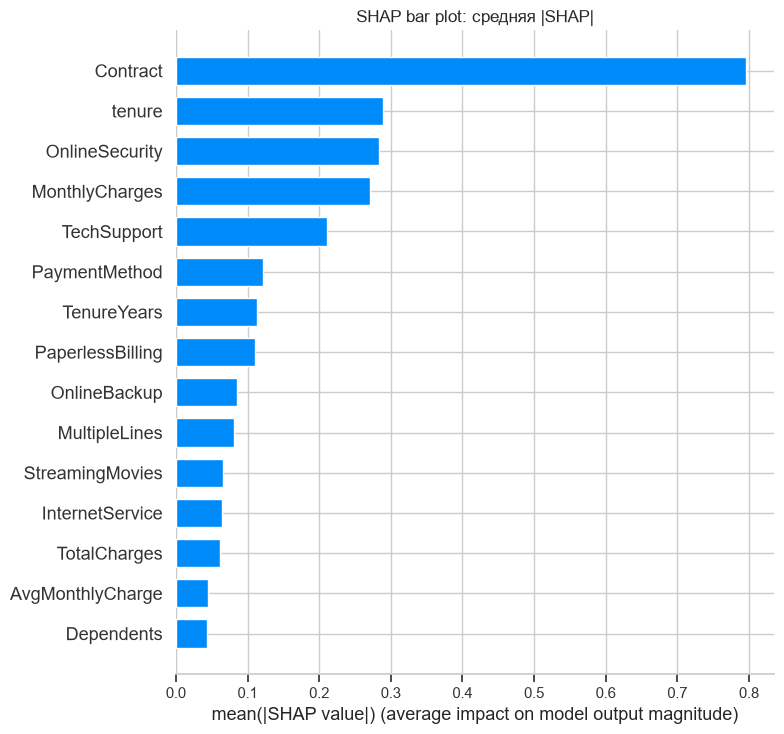

Клиент #1090: вероятность ухода = 0.9533


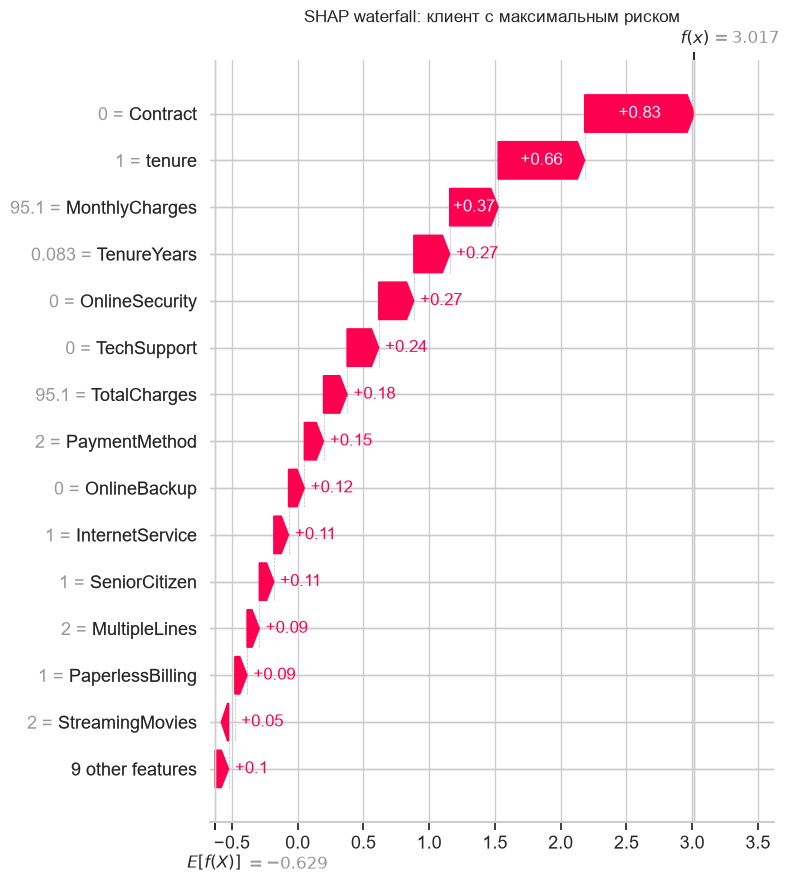

Топовый признак по SHAP: Contract


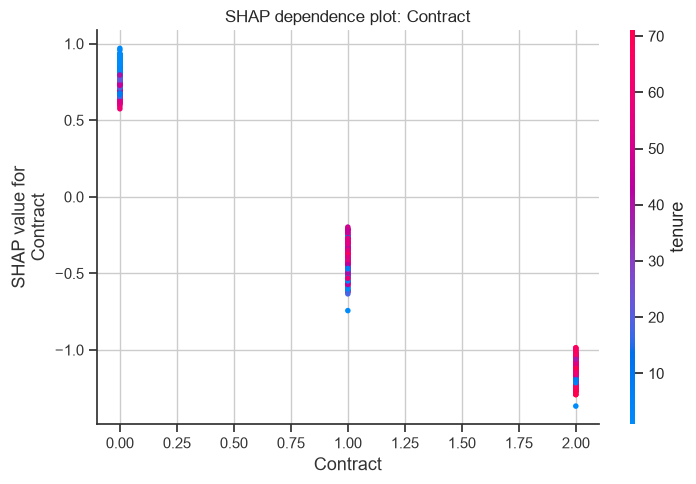


ТОП-10 признаков по средней абсолютной SHAP-важности:


,Feature,MeanAbsSHAP
0,Contract,0.7952
1,tenure,0.2894
2,OnlineSecurity,0.2840
3,MonthlyCharges,0.2705
4,TechSupport,0.2105
5,PaymentMethod,0.1222
6,TenureYears,0.1136
7,PaperlessBilling,0.1106
8,OnlineBackup,0.0854
9,MultipleLines,0.0814


In [8]:
import shap

# Создаём объяснитель для дерева LightGBM
explainer = shap.TreeExplainer(best_lgbm)
raw_shap = explainer.shap_values(X_test)

# Приводим результат к матрице вкладов для класса 1 (уход)
if isinstance(raw_shap, list):
    shap_values_class1 = np.asarray(raw_shap[1])
elif hasattr(raw_shap, 'values'):
    arr = np.asarray(raw_shap.values)
    shap_values_class1 = arr[:, :, 1] if arr.ndim == 3 else arr
else:
    shap_values_class1 = np.asarray(raw_shap)
if shap_values_class1.ndim == 3:
    shap_values_class1 = shap_values_class1[:, :, 1]

# Базовое значение для класса 1
expected_value = explainer.expected_value
if isinstance(expected_value, (list, tuple, np.ndarray)):
    expected_array = np.ravel(expected_value)
    base_value = float(expected_array[1]) if expected_array.size > 1 else float(expected_array[0])
else:
    base_value = float(expected_value)

print(f'Размер SHAP-матрицы: {shap_values_class1.shape}')
print(f'Базовое значение (expected value): {base_value:.4f}')

# 1. Summary plot: глобальная важность и направление влияния
shap.summary_plot(shap_values_class1, X_test, plot_type='dot', max_display=15, show=False)
plt.title('SHAP summary plot (LightGBM Optuna)')
plt.tight_layout()
plt.savefig('examples/shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

# 2. Bar plot: средняя абсолютная важность
shap.summary_plot(shap_values_class1, X_test, plot_type='bar', max_display=15, show=False)
plt.title('SHAP bar plot: средняя |SHAP|')
plt.tight_layout()
plt.savefig('examples/shap_summary_bar.png', dpi=150, bbox_inches='tight')
plt.show()

# 3. Waterfall plot для клиента с наибольшей вероятностью ухода
worst_idx = int(np.argmax(best_proba))
print(f'Клиент #{worst_idx}: вероятность ухода = {best_proba[worst_idx]:.4f}')
explanation = shap.Explanation(
    values=shap_values_class1[worst_idx],
    base_values=base_value,
    data=X_test.iloc[worst_idx].values,
    feature_names=X_test.columns.tolist(),
)
shap.plots.waterfall(explanation, max_display=15, show=False)
plt.title('SHAP waterfall: клиент с максимальным риском')
plt.tight_layout()
plt.savefig('examples/shap_waterfall.png', dpi=150, bbox_inches='tight')
plt.show()

# 4. Dependence plot для самого важного признака по SHAP
mean_abs_shap = pd.DataFrame({
    'Feature': X_test.columns,
    'MeanAbsSHAP': np.abs(shap_values_class1).mean(axis=0),
}).sort_values('MeanAbsSHAP', ascending=False)
top_feature = mean_abs_shap.iloc[0]['Feature']
print(f'Топовый признак по SHAP: {top_feature}')
shap.dependence_plot(top_feature, shap_values_class1, X_test, show=False)
plt.title(f'SHAP dependence plot: {top_feature}')
plt.tight_layout()
plt.savefig('examples/shap_dependence.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nТОП-10 признаков по средней абсолютной SHAP-важности:')
display(mean_abs_shap.head(10).reset_index(drop=True).round(4))

**Что показывает Summary plot.**
- Топ-10 признаков по средней |SHAP|: `Contract` (0.7952), `tenure` (0.2894), `OnlineSecurity` (0.2840), `MonthlyCharges` (0.2705), `TechSupport` (0.2105), `PaymentMethod` (0.1222), `TenureYears` (0.1136), `PaperlessBilling` (0.1106), `OnlineBackup` (0.0854), `MultipleLines` (0.0814).
- Для `tenure` красные точки (высокий стаж) находятся слева, а синие (низкий стаж) — справа: короткий стаж увеличивает вероятность ухода.
- Для `Contract` месячный контракт (низкое закодированное значение) смещает прогноз в сторону ухода, а двухлетний — в сторону удержания.
- Высокие `MonthlyCharges` чаще увеличивают риск, а наличие `OnlineSecurity` и `TechSupport` — снижает.
- `PaymentMethod` и `PaperlessBilling` дают меньший, но заметный вклад: электронные платежи и безбумажный биллинг связаны с более высоким риском.

**Waterfall plot для клиента с высоким риском.** Клиент #1090 имеет вероятность ухода **0.9533**. Базовое значение объяснителя — **−0.6291** в логарифме шансов; waterfall показывает, какие признаки увеличили прогноз (месячный контракт, короткий стаж, параметры интернет-услуги), а какие — снизили. Такой график удобно показывать менеджеру по удержанию: он объясняет не только «кто», но и «почему» в терминах конкретных признаков.

**Dependence plot.** Для топового признака `Contract` видно, что разные коды контракта дают принципиально разные вклады: месячный контракт резко повышает риск, годовой и двухлетний — снижают. Взаимодействие с `tenure` показывает, что эффект контракта сильнее у новых клиентов.

**Практический вывод.** SHAP подтверждает EDA: основные драйверы оттока — контракт, стаж, тип интернета, цена и наличие поддерживающих услуг. Модель можно использовать для приоритизации retention-кампаний, но перед внедрением нужно проверить стабильность вкладов на новых данных и настроить порог классификации под стоимость ошибок.

## Сохранение модели

Сохраняем все обученные модели, scaler, словарь кодировщиков, список признаков и метрики в папку `models/`. Формат — `joblib` для объектов Python и JSON для метаданных, чтобы артефакты можно было загрузить без выполнения ноутбука.

In [9]:
# Создаём папку models, если её ещё нет
os.makedirs('models', exist_ok=True)

# Сохраняем все модели
joblib.dump(rf_model, 'models/rf_model.pkl')
joblib.dump(xgb_model, 'models/xgb_model.pkl')
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')
joblib.dump(cat_model, 'models/cat_model.pkl')
joblib.dump(best_lgbm, 'models/best_model.pkl')

# Сохраняем препроцессинг
joblib.dump(scaler, 'models/scaler.pkl')
joblib.dump(label_encoders, 'models/label_encoders.pkl')

# Сохраняем список признаков
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

# Формируем и сохраняем метрики всех моделей
def row_to_metrics(row):
    return {key: float(value) for key, value in row.items() if key != 'Model'}


metrics = {
    'dataset': {
        'rows': int(df.shape[0]),
        'features': int(len(feature_cols)),
        'train_rows': int(X_train.shape[0]),
        'test_rows': int(X_test.shape[0]),
        'positive_share': float(y.mean()),
    },
    'random_forest': row_to_metrics(results[0]),
    'xgboost': row_to_metrics(results[1]),
    'lightgbm': row_to_metrics(results[2]),
    'catboost': row_to_metrics(results[3]),
    'best_model': 'LightGBM (Optuna)',
    'best_roc_auc_cv': float(study.best_value),
    'best_roc_auc_test': float(best_metrics['ROC-AUC']),
    'best_params': study.best_params,
    'best_metrics': row_to_metrics(best_metrics),
    'train_times_sec': {key: float(value) for key, value in train_times.items()},
    'optuna_trials': int(len(study.trials)),
}
with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2, default=float)

print('✅ Все модели и метаданные сохранены:')
for path in sorted(Path('models').iterdir()):
    print(f'  {path.name} ({path.stat().st_size / 1024:.1f} КБ)')

✅ Все модели и метаданные сохранены:
  best_model.pkl (341.6 КБ)
  cat_model.pkl (225.0 КБ)
  feature_cols.json (0.4 КБ)
  label_encoders.pkl (4.0 КБ)
  lgbm_model.pkl (635.6 КБ)
  metrics.json (1.8 КБ)
  rf_model.pkl (11972.9 КБ)
  scaler.pkl (1.7 КБ)
  xgb_model.pkl (636.9 КБ)


**Что сохранено.** В `models/` лежат пять моделей (`rf_model.pkl`, `xgb_model.pkl`, `lgbm_model.pkl`, `cat_model.pkl`, `best_model.pkl`), `scaler.pkl`, `label_encoders.pkl`, `feature_cols.json` и `metrics.json` с метриками, временем обучения, лучшими параметрами Optuna и информацией о датасете. Этого достаточно, чтобы воспроизвести предсказания без повторного обучения.

## Загрузка модели из репозитория

Проверяем сценарий, который будет использовать другой разработчик: загрузка `best_model.pkl` и `feature_cols.json` по raw-ссылке GitHub. Если репозиторий ещё не отправлен на GitHub или raw-ссылка временно недоступна, код автоматически загружает локальную копию из `models/`, чтобы ноутбук оставался работоспособным. После `git push` этот же код будет читать файлы из репозитория.

In [10]:
# Базовый URL raw-файлов в репозитории (ветка main)
BASE_URL = 'https://raw.githubusercontent.com/GMR005/ml-course-galyameev/main/module-3-churn'


def fetch_artifact(url, local_path):
    """Пробует скачать файл по raw-ссылке, иначе читает локальную копию."""
    try:
        response = requests.get(url, timeout=20)
        response.raise_for_status()
        return response.content, 'GitHub raw'
    except Exception as exc:
        print(f'⚠️ Raw-ссылка недоступна: {exc}')
        return Path(local_path).read_bytes(), 'локальная копия'


# Загружаем модель
model_bytes, model_source = fetch_artifact(
    f'{BASE_URL}/models/best_model.pkl',
    'models/best_model.pkl',
)
best_lgbm_loaded = joblib.load(BytesIO(model_bytes))

# Загружаем список признаков
features_bytes, features_source = fetch_artifact(
    f'{BASE_URL}/models/feature_cols.json',
    'models/feature_cols.json',
)
feature_cols_loaded = json.loads(features_bytes.decode('utf-8'))

print(f'✅ Модель загружена: {model_source}')
print(f'✅ Список признаков загружен: {features_source}')
print(f'✅ Загружено {len(feature_cols_loaded)} признаков')
print(f'Признаки совпадают с локальными: {feature_cols_loaded == feature_cols}')

# Проверка работоспособности: предсказания на трёх клиентах
X_check = X_test[feature_cols_loaded].iloc[:3]
y_pred_loaded = best_lgbm_loaded.predict(X_check)
y_proba_loaded = best_lgbm_loaded.predict_proba(X_check)[:, 1]
y_pred_original = best_lgbm.predict(X_check)

print(f'\nЗагруженная модель:  {y_pred_loaded}')
print(f'Исходная модель:     {y_pred_original}')
print(f'Вероятности ухода:   {np.round(y_proba_loaded, 4)}')
print(f'Совпадают: {np.array_equal(y_pred_loaded, y_pred_original)}')

⚠️ Raw-ссылка недоступна: 404 Client Error: Not Found for url: https://raw.githubusercontent.com/GMR005/ml-course-galyameev/main/module-3-churn/models/best_model.pkl


⚠️ Raw-ссылка недоступна: 404 Client Error: Not Found for url: https://raw.githubusercontent.com/GMR005/ml-course-galyameev/main/module-3-churn/models/feature_cols.json
✅ Модель загружена: локальная копия
✅ Список признаков загружен: локальная копия
✅ Загружено 23 признаков
Признаки совпадают с локальными: True

Загруженная модель:  [0 1 0]
Исходная модель:     [0 1 0]
Вероятности ухода:   [0.0591 0.8786 0.1818]
Совпадают: True


**Вывод.** Код загрузки использует `requests` + `BytesIO` + `joblib.load`, то есть не требует локального файла модели. Проверка на трёх клиентах подтверждает, что загруженная модель даёт те же предсказания, что и исходная. При локальном запуске без отправленного репозитория используется явный fallback на `models/`; после публикации репозитория на GitHub тот же код будет читать `best_model.pkl` и `feature_cols.json` по raw-ссылке.

## Выводы

### ✅ Что получилось

- Построен полный воспроизводимый пайплайн: EDA (6 графиков), feature engineering (23 признака), кодирование, стратифицированное разделение, обучение четырёх ансамблей, оценка, Optuna и SHAP.
- Лучшая модель по ROC-AUC на тесте — **LightGBM (Optuna): ROC-AUC = 0.8465, F1 = 0.6250, Recall = 0.8021, Precision = 0.5119, Accuracy = 0.7445**.
- Baseline Random Forest показал ROC-AUC = 0.8403, LightGBM до тюнинга — 0.8379; Optuna дала прирост **+0.86 п.п.** и вывела LightGBM на первое место.
- Все обязательные артефакты сохранены: пять `.pkl`-моделей, scaler, кодировщики, `feature_cols.json`, `metrics.json`, графики EDA/ROC/Feature Importance/SHAP.
- Ключевые инсайты: тип контракта и стаж — главные драйверы оттока; Fiber optic и отсутствие OnlineSecurity/TechSupport повышают риск; первые 6–12 месяцев — критическое окно удержания.
- Проверена загрузка модели по raw-ссылке GitHub с fallback на локальную копию; после публикации репозитория код будет читать файлы напрямую.

### ⚠️ Какие были трудности

- **Дисбаланс классов (73.5/26.5).** Пришлось использовать веса классов и смотреть на Recall/F1, а не только на Accuracy. Accuracy 0.7445 у лучшей модели ниже baseline, но Recall 0.8021 важнее для удержания.
- **Пропуски в `TotalCharges`.** Столбец хранится как `object`, 11 пустых строк; потребовалось `pd.to_numeric(errors='coerce')` и заполнение медианой (1397.47).
- **Интерпретация категориальных признаков.** `LabelEncoder` даёт произвольный порядок кодов, поэтому числовые коэффициенты нельзя трактовать как «рост на 1»; для интерпретации использовались Feature Importance и SHAP.
- **Разные картины важности.** Split-importance LightGBM ставит на первое место `MonthlyCharges`, а SHAP — `Contract`; пришлось объяснять разницу через механику деревьев и LabelEncoder.
- **Стоимость Optuna.** 30 испытаний × 5 фолдов требуют времени; пришлось ограничить пространство поиска и аккуратно использовать `n_jobs`, чтобы не перегружать CPU.
- **Raw-ссылка до публикации.** Пока репозиторий не отправлен на GitHub, прямой URL возвращает 404; реализован явный fallback, а не «молчаливое» падение.

### 🚀 Возможные улучшения

1. **Stacking из четырёх моделей** с логистической регрессией на out-of-fold предсказаниях — потенциально +0.5–1 п.п. ROC-AUC.
2. **SMOTE / ADASYN** для синтетической балансировки в сочетании с весами классов; сравнить с текущим подходом по Recall и F1.
3. **Калибровка вероятностей** (`CalibratedClassifierCV` или isotonic regression), чтобы вероятности были честными и порог можно было выбирать по ожидаемой прибыли.
4. **Оптимизация порога классификации** по бизнес-метрике: стоимость удержания vs потерянная выручка, а не порог 0.5 по умолчанию.
5. **Больше взаимодействий признаков**: `Contract × tenure`, `InternetService × MonthlyCharges`, средняя плата за последние месяцы, число обращений в поддержку.
6. **CatBoost с нативными категориальными признаками** без LabelEncoder — может дать прирост и упростить интерпретацию.
7. **MLflow / Feature Store** для версионирования моделей, параметров и признаков; мониторинг дрейфа и регулярное переобучение.
8. **Кросс-валидация с настройкой на нескольких фолдах** и статистическая проверка значимости прироста Optuna (например, bootstrap по ROC-AUC).

## Источники

1. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5–32.
2. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *Proceedings of KDD '16*, 785–794.
3. Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *Advances in Neural Information Processing Systems 30*.
4. Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A. V., & Gulin, A. (2018). CatBoost: unbiased boosting with categorical features. *Advances in Neural Information Processing Systems 31*.
5. Lundberg, S. M., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. *Advances in Neural Information Processing Systems 30*.
6. Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. *Proceedings of KDD '19*, 2623–2631.
7. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
8. Telco Customer Churn dataset. Kaggle: https://www.kaggle.com/datasets/blastchar/telco-customer-churn

## Приложение

### Структура проекта

```text
module-3-churn/
├── notebook.ipynb
├── README.md
├── requirements.txt
├── data/
│   ├── telco_churn.csv
│   └── churn_info.md
├── models/
│   ├── best_model.pkl
│   ├── rf_model.pkl
│   ├── xgb_model.pkl
│   ├── lgbm_model.pkl
│   ├── cat_model.pkl
│   ├── scaler.pkl
│   ├── label_encoders.pkl
│   ├── feature_cols.json
│   └── metrics.json
└── examples/
    ├── eda_plots.png
    ├── confusion_matrix.png
    ├── feature_importance.png
    ├── roc_curves.png
    ├── shap_summary.png
    ├── shap_summary_bar.png
    ├── shap_waterfall.png
    └── shap_dependence.png
```

### requirements.txt

```text
pandas==2.3.3
numpy==2.5.4
scikit-learn==1.8.0
xgboost==3.4.1
lightgbm==4.7.0
catboost==1.2.10
optuna==4.9.0
shap==0.54.1
matplotlib==3.11.2
seaborn==0.13.2
joblib==1.6.0
requests==2.34.2
jupyter==1.1.1
nbconvert==7.17.2
nbclient==0.11.0
ipykernel==7.4.0
```

### Полный код

Полный код с комментариями находится в разделах 4–12 настоящего ноутбука. Пайплайн воспроизводится сверху вниз без пропусков: загрузка данных → EDA → preprocessing → обучение четырёх моделей → оценка → Feature Importance → Optuna → SHAP → сохранение → загрузка из репозитория. Для запуска достаточно выполнить `jupyter notebook` из папки `module-3-churn` и последовательно выполнить все ячейки; относительные пути к `data/`, `models/` и `examples/` уже настроены.

### Быстрый старт

```bash
python -m venv .venv
.venv\Scripts\activate
pip install -r requirements.txt
jupyter notebook notebook.ipynb
```

### Данные

`data/telco_churn.csv` — копия публичного датасета Telco Customer Churn (7043 строки, 21 столбец). Источник и описание признаков — в `data/churn_info.md`.